# Домашнє завдання 4: три прості діаграми й висновки

Ім’я: Наталя Шкандала

Збережіть цей файл як **lesson4_homework.ipynb** (File → Save As). Заповнюйте клітинки по черзі. Наприкінці запустіть усе: **Run All**.

Дані навчальні (вигадані). Можна взяти свій набір даних із домашнього завдання 3.

##Додатковий коментар для викладачки##: я зробила додатковий файл під назвою upd (не затирала) і використала дані з попереднього ДЗ (coffee_value_benchmark.csv)



## Крок 1. Запитання

Одне речення: яке запитання ви ставите й для кого.

Приклад: «Яка точка продає більше кави? Для власниці кав’ярні».

**Моє запитання:**

 Моє запитання: Який метод обробки кави забезпечує найвищу середню ціну та чи залежить ціна за кілограм від оцінки якості зерна? Для власниці кавового бізнесу або закупника зерна.

### Дані
Запустіть клітинку: вона створює таблиці `sales` (продажі) і `prices` (ціни). Якщо берете свої дані — замініть код на `df = pd.read_csv("ваш_файл.csv")`.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("coffee_value_benchmark.csv")

print(df.shape)
print(df.head(3))

(35700, 36)
     record_id       lot_id harvest_season  harvest_calendar_year  \
0  REC-0000001  LOT-0032936        2020/21                   2020   
1  REC-0000002  LOT-0030952        2021/22                   2022   
2  REC-0000003  LOT-0018572        2020/21                   2020   

   harvest_month country_of_origin    farm_type  farm_size_hectares  \
0             10           Vietnam  Smallholder                0.58   
1              1          Honduras  Smallholder                1.12   
2             11           Vietnam  Cooperative               13.82   

   tree_age_years  altitude_mean_meters  ... lot_size_kg  roast_level  \
0            28.0                1961.0  ...     26433.0       Medium   
1             2.0                1257.0  ...     25446.0       Medium   
2             5.0                 557.0  ...     15707.0       Medium   

   acidity_score  sweetness_score body_score aroma_score  flavor_score  \
0           7.95             7.30       8.45        7.35   

## Крок 2. Цифри

Порахуйте `groupby` (суми або середні за групами) і `describe()` для однієї числової колонки.

##Підказка: `sales.groupby("shop")["cups"].sum()` і `sales["cups"].describe()`

In [2]:
# groupby
print(df.groupby("processing_method")["price_usd_per_kg"].mean().round(2))

processing_method
Anaerobic    5.77
Honey        5.05
Natural      4.62
Washed       4.89
Name: price_usd_per_kg, dtype: float64


In [3]:
# describe()
print(df["price_usd_per_kg"].describe().round(2))

count    35700.00
mean         4.81
std          2.20
min          1.78
25%          3.46
50%          4.18
75%          5.36
max         22.85
Name: price_usd_per_kg, dtype: float64


## Крок 3. Три діаграми

У кожної — назва (`plt.title`) і підписи осей (`plt.xlabel`, `plt.ylabel`). 1–3 кольори, без зайвих прикрас.

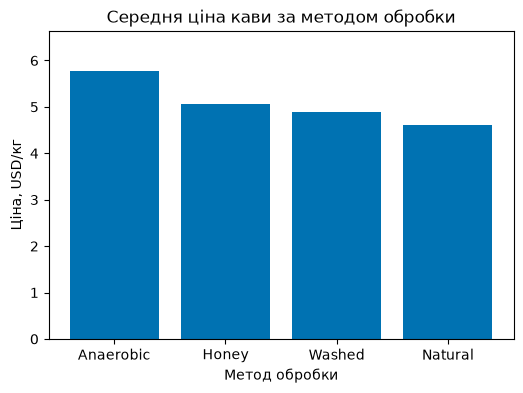

In [4]:
import matplotlib.pyplot as plt

by_method = df.groupby("processing_method")["price_usd_per_kg"].mean().sort_values(ascending=False)

plt.figure(figsize=(6, 4))
plt.bar(by_method.index, by_method.values, color="#0072B2")
plt.ylim(0, by_method.max() * 1.15)
plt.title("Середня ціна кави за методом обробки")
plt.xlabel("Метод обробки")
plt.ylabel("Ціна, USD/кг")
plt.show()

**Крок 4 — висновок 1 (одне речення):

** Найвищу середню ціну має кава анаеробної обробки (5.77 USD/кг), далі йдуть Honey (5.05 USD/кг) та Washed (4.89 USD/кг), а найнижчу — натуральна обробка (4.62 USD/кг).

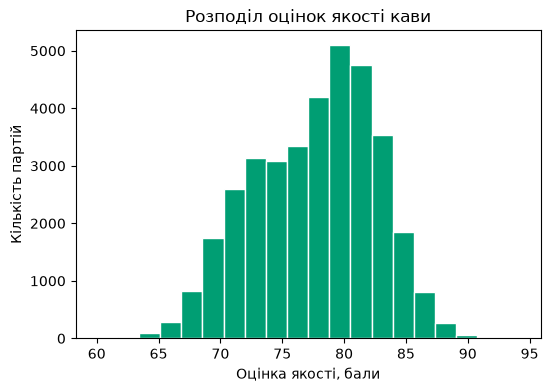

Середня оцінка якості: 77.6


In [5]:
# Діаграма 2: лінія (зміна в часі) або гістограма (розподіл оцінок якості кави)
plt.figure(figsize=(6, 4))
plt.hist(df["coffee_quality_score"], bins=20, color="#009E73", edgecolor="white")
plt.title("Розподіл оцінок якості кави")
plt.xlabel("Оцінка якості, бали")
plt.ylabel("Кількість партій")
plt.show()

print("Середня оцінка якості:", round(df["coffee_quality_score"].mean(), 1))

**Крок 4 — висновок 2 (одне речення):** Більшість партій кави мають оцінки в межах від 75 до 82 балів (середнє — 77.6 балів), утворюючи симетричний розподіл навколо центру.

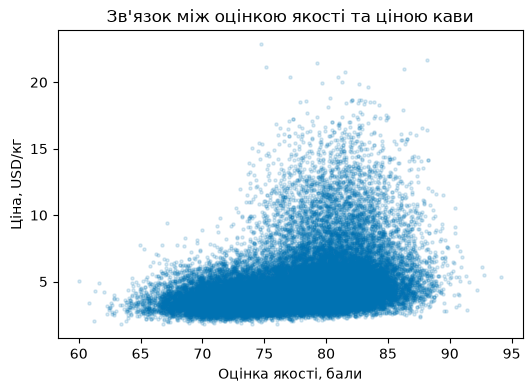

Кореляція якості та ціни: 0.33


In [6]:
# Діаграма 3: scatter — зв'язок двох чисел - оцінки якості та ціни кави
plt.figure(figsize=(6, 4))
plt.scatter(df["coffee_quality_score"], df["price_usd_per_kg"], color="#0072B2", alpha=0.15, s=5)
plt.title("Зв'язок між оцінкою якості та ціною кави")
plt.xlabel("Оцінка якості, бали")
plt.ylabel("Ціна, USD/кг")
plt.show()

print("Кореляція якості та ціни:", round(df["coffee_quality_score"].corr(df["price_usd_per_kg"]), 2))

**Крок 4 — висновок 3 (одне речення):** Кореляція між якістю та ціною становить 0.33 (за шкалою від −1 до 1, де 1 — це повний збіг зростання): тобто спостерігається зв’язок, але він є помірний, і зі зростанням оцінки якості понад 75–80 балів ціна помітно підвищується, але не є єдиним чинником вартості

## Крок 5. Перевірка однієї діаграми

Яку діаграму перевірили: діаграма 1 — стовпчикова діаграма середньої ціни кави за методом обробки.

- [Х] вісь стовпчиків починається від нуля
- [Х] є назва й підписи осей
- [Х] зрозуміло без пояснень

## AI (за бажанням)

**Мій запит:** Який колір краще використати для ділової гістограми замість, напр.,  яскраво-помаранчевого (спочатку обрала його), щоб графік добре читався для власниці або власника бізнесу, та як вивести середнє значення й кореляцію без зайвих прикрас?

**Що відповів AI:** Запропонував замінити помаранчевий колір на спокійний зелений (`#009E73`) або синій (`#0072B2`), додати білі межі стовпчиків (`edgecolor="white"`) та вивести точні значення під графіками через `print()`.

**Як я перевірила:** Звірила коди кольорів із конспектом уроку (палітра Okabe–Ito), запустила код у ноутбуці та перевірила, що середня оцінка якості (77.6) і кореляція (0.33) збігаються з розрахунками `describe()` і `corr()`.

Не вставляйте в чат особисті дані, паролі чи ключі.

## Крок 6. Перед здачею

Kernel → Restart → **Run All**. Перевірте, що всі три діаграми видно. Здайте файл у Moodle або через Git (див. текст завдання).